   is_member  period  profit        group
0      False   After  156.59  Non-members
1      False  Before  341.00  Non-members
2       True   After  714.70      Members
3       True  Before  870.30      Members


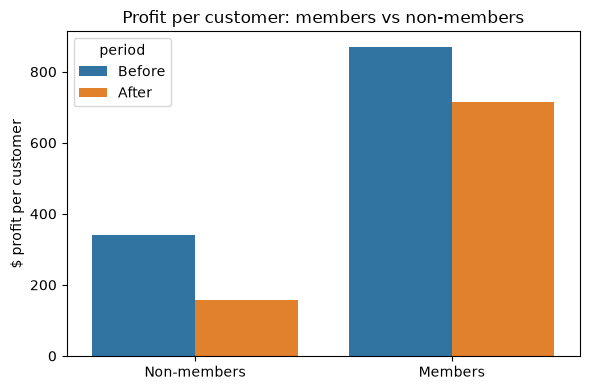

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../../data/processed/lululime_clean.csv")
df["date"] = pd.to_datetime(df["date"])
df["is_member"] = df["loyalty_join_date"].notna()
launch = pd.Timestamp("2024-06-01")

# 12 months before and after launch
df = df[(df["date"] >= launch - pd.DateOffset(months=12)) &
        (df["date"] <  launch + pd.DateOffset(months=12))].copy()
df["period"] = np.where(df["date"] < launch, "Before", "After")

# Revenue and cost per row
is_sale = df["row_type"].isin(["Purchase", "Return"])
df["revenue"] = np.where(is_sale, df["quantity"] * df["unit_price_paid"], 0)
df["cost"] = np.where(is_sale, df["quantity"] * df["production_cost"],
                      np.where(df["row_type"] == "Repair Drop-off", df["production_cost"], 0))

# Redeemed points: sum per transaction, then convert to dollars (20 pts = $1)
tx = df.groupby(["transaction_id", "customer_id", "period"])["points_redeemed"].sum().reset_index()
redeem = (tx.groupby(["customer_id", "period"])["points_redeemed"].sum() / 20).rename("redeem_cost")

# Profit per customer
cust = (df.groupby(["customer_id", "period", "is_member"])
          .agg(revenue=("revenue", "sum"), cost=("cost", "sum"))
          .reset_index()
          .merge(redeem.reset_index(), on=["customer_id", "period"], how="left"))
cust["redeem_cost"] = cust["redeem_cost"].fillna(0)
cust["profit"] = cust["revenue"] - cust["cost"] - cust["redeem_cost"]

# Average profit per customer
summary = cust.groupby(["is_member", "period"])["profit"].mean().reset_index()
summary["group"] = summary["is_member"].map({True: "Members", False: "Non-members"})
print(summary.round(2))

# Chart
plt.figure(figsize=(6, 4))
sns.barplot(data=summary, x="group", y="profit", hue="period",
            order=["Non-members", "Members"], hue_order=["Before", "After"])
plt.title("Profit per customer: members vs non-members")
plt.xlabel("")
plt.ylabel("$ profit per customer")
plt.tight_layout()
plt.show()

           bucket  transactions  return_rate
0  0% (no points)        133425          9.5
1           1-25%         25580         10.5
2          26-50%          5861          9.8
3            >50%          3617         23.7


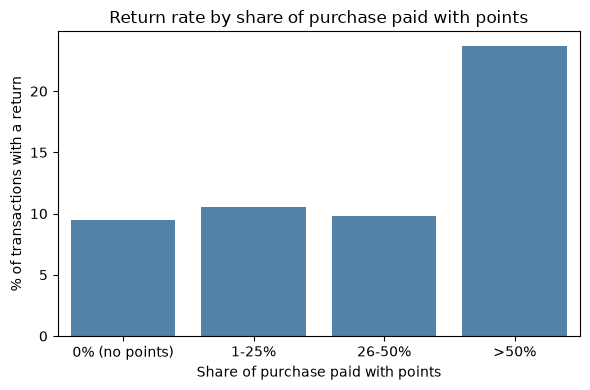

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("../../data/processed/lululime_clean.csv")
df["date"] = pd.to_datetime(df["date"])

# --- 1. One row per purchase transaction ---
buys = df[df["row_type"] == "Purchase"].copy()
buys["revenue"] = buys["quantity"] * buys["unit_price_paid"]

tx = (buys.groupby("transaction_id")
          .agg(revenue=("revenue", "sum"),
               points_redeemed=("points_redeemed", "sum"))  # sum per transaction, as the case says
          .reset_index())

# --- 2. Share of the purchase paid with points (20 pts = $1) ---
tx["points_share"] = (tx["points_redeemed"] / 20) / tx["revenue"]
tx = tx[tx["revenue"] > 0]
tx["points_share"] = tx["points_share"].clip(upper=1)

tx["bucket"] = pd.cut(
    tx["points_share"],
    bins=[-0.001, 0, 0.25, 0.5, 1.0],
    labels=["0% (no points)", "1-25%", "26-50%", ">50%"],
)

# --- 3. Was any item from this transaction returned? ---
returned_ids = df.loc[df["row_type"] == "Return", "original_transaction_id"].unique()
tx["returned"] = tx["transaction_id"].isin(returned_ids)

# --- 4. Return rate by bucket ---
summary = (tx.groupby("bucket", observed=True)
             .agg(transactions=("transaction_id", "count"),
                  return_rate=("returned", "mean"))
             .reset_index())
summary["return_rate"] = (summary["return_rate"] * 100).round(1)
print(summary)

# --- 5. Chart ---
plt.figure(figsize=(6, 4))
sns.barplot(data=summary, x="bucket", y="return_rate", color="steelblue")
plt.title("Return rate by share of purchase paid with points")
plt.xlabel("Share of purchase paid with points")
plt.ylabel("% of transactions with a return")
plt.tight_layout()
plt.show()